In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

First 5 rows of the dataset:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseValue  
0    -122.23          4.526  
1    -122.22          3.585  
2    -122.24          3.521  
3    -122.25          3.413  
4    -122.25          3.422  

Missing values in each column:
MedInc           0
HouseAge         0
AveRooms         0
AveBedrms        0
Population       0
AveOccup         0
Latitude         0
Longitude        0
MedHouseValue    0
dtype: int64


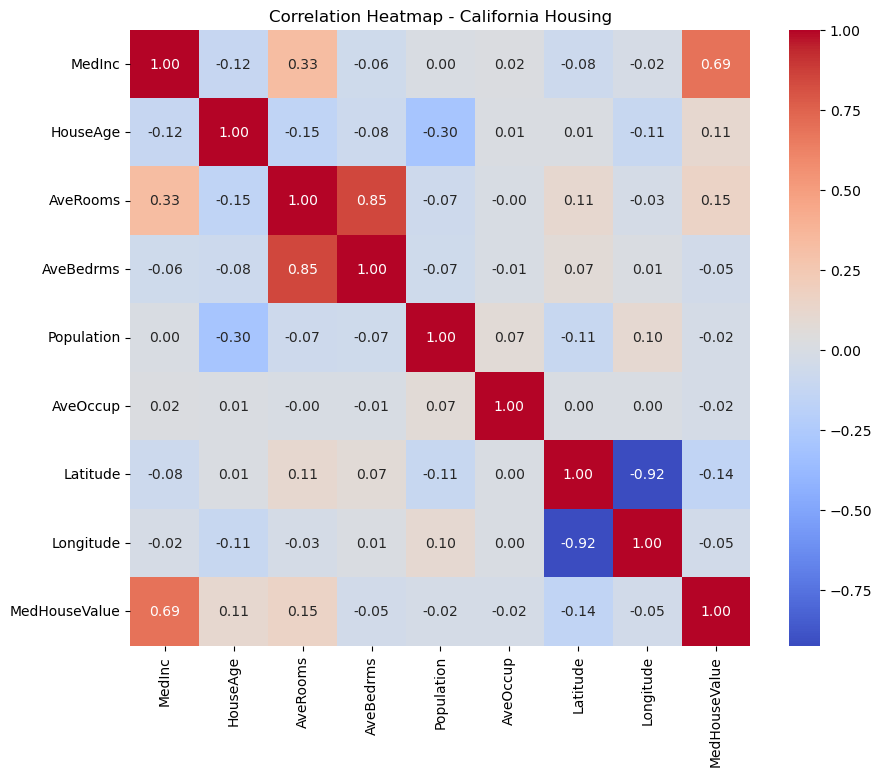

In [2]:
california = fetch_california_housing()
df = pd.DataFrame(data=california.data, columns=california.feature_names)
df['MedHouseValue'] = california.target  

print("First 5 rows of the dataset:")
print(df.head())

#(Null values)
print("\nMissing values in each column:")
print(df.isnull().sum())

#(Correlation Heatmap)
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap - California Housing")
plt.show()

In [3]:
X = df.drop(columns=['MedHouseValue'])
y = df['MedHouseValue']

# تقسيم البيانات بنسبة 80% تدريب و 20% اختبار
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [4]:
# 1.(Ordinary Least Squares - OLS)
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)
y_pred_ols = ols.predict(X_test_scaled)

# 2. نموذج Ridge باستخدام GridSearchCV لاختيار أفضل alpha
ridge = Ridge()
param_grid_ridge = {'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}
grid_ridge = GridSearchCV(estimator=ridge, param_grid=param_grid_ridge, cv=5, scoring='neg_mean_squared_error')
grid_ridge.fit(X_train_scaled, y_train)

best_ridge = grid_ridge.best_estimator_
y_pred_ridge = best_ridge.predict(X_test_scaled)
print(f"Best Ridge Alpha: {grid_ridge.best_params_['alpha']}")

# 3. نموذج Lasso باستخدام GridSearchCV لاختيار أفضل alpha
lasso = Lasso()
param_grid_lasso = {'alpha': [0.0001, 0.001, 0.01, 0.1, 1.0]}
grid_lasso = GridSearchCV(estimator=lasso, param_grid=param_grid_lasso, cv=5, scoring='neg_mean_squared_error')
grid_lasso.fit(X_train_scaled, y_train)

best_lasso = grid_lasso.best_estimator_
y_pred_lasso = best_lasso.predict(X_test_scaled)
print(f"Best Lasso Alpha: {grid_lasso.best_params_['alpha']}")

Best Ridge Alpha: 0.1
Best Lasso Alpha: 0.001


In [5]:
def evaluate_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {model_name} Performance ---")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE:  {mae:.4f}")
    print(f"R²:   {r2:.4f}\n")

evaluate_model(y_test, y_pred_ols, "OLS Linear Regression")
evaluate_model(y_test, y_pred_ridge, "Ridge Regression")
evaluate_model(y_test, y_pred_lasso, "Lasso Regression")

--- OLS Linear Regression Performance ---
RMSE: 0.7456
MAE:  0.5332
R²:   0.5758

--- Ridge Regression Performance ---
RMSE: 0.7456
MAE:  0.5332
R²:   0.5758

--- Lasso Regression Performance ---
RMSE: 0.7446
MAE:  0.5331
R²:   0.5769



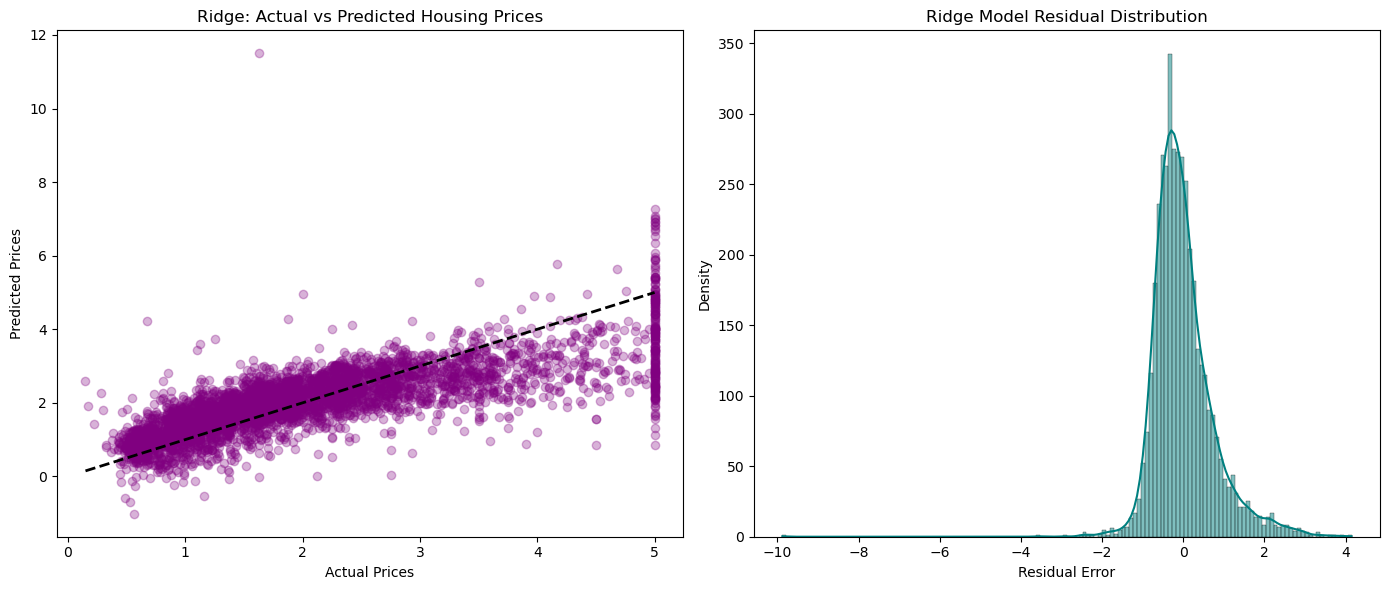

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Predicted vs Actual (Ridge Model Example)
axes[0].scatter(y_test, y_pred_ridge, alpha=0.3, color='purple')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
axes[0].set_xlabel('Actual Prices')
axes[0].set_ylabel('Predicted Prices')
axes[0].set_title('Ridge: Actual vs Predicted Housing Prices')

# 2. Residual Distribution (Errors)
residuals = y_test - y_pred_ridge
sns.histplot(residuals, kde=True, ax=axes[1], color='teal')
axes[1].set_title('Ridge Model Residual Distribution')
axes[1].set_xlabel('Residual Error')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.show()